## Preguntas a responder


- 1 La arquitectura del sistema es orientado a objetos?
- 2 El sistema debe dar la instruccion de que el carro se mueva

## Instalacion de las importacion de las librerias que se necesitarian

In [ ]:
pip install opencv-python numpy matplotlib

## Importacion de las librerias

In [15]:
# ============================================================
# LANE DEPARTURE AVOIDANCE
# LANE-CHANGE VALIDATION
# ============================================================
#
# Proyecto de Movilidad Inteligente
#
# Arquitectura inicial:
#
# Sensores
#    ↓
# Percepción
#    ↓
# Estado del vehículo + geometría del carril
#    ↓
# Errores lateral / orientación
#    ↓
# Control de dirección
#    ↓
# Modelo cinemático de bicicleta
#    ↓
# Lane Departure
#    ↓
# Lane Change Validation
#    ↓
# TRUE / FALSE
#
# Esta primera versión utiliza datos simulados.
# Posteriormente se sustituirán por datos reales.
# ============================================================
import cv2
import numpy as np
import matplotlib.pyplot as plt

## Parametros del vehiculo

In [16]:
# VEHICLE PARAMETERS
VEHICLE_LENGTH = 4.96       # m
WHEELBASE = 2.90            # m
VEHICLE_WIDTH = 1.96        # m
VEHICLE_MASS = 2150         # kg

# VEHICLE STATE
VEHICLE_SPEED = 15.0        # m/s
VEHICLE_YAW = 0.0           # rad
VEHICLE_YAW_RATE = 0.0      # rad/s
STEERING_ANGLE = 0.0        # rad

# LANE PARAMETERS
LANE_WIDTH = 3.5            # m
LANE_CENTER = 0.0           # m
LANE_HEADING = 0.0          # rad

# CONTROL PARAMETERS
K_LATERAL = 0.8
K_HEADING = 1.2

MAX_STEERING_ANGLE = np.deg2rad(30)

# SIMULATION PARAMETERS
DT = 0.05                   # seconds
SIMULATION_TIME = 10.0      # seconds

# SAFETY PARAMETERSMIN_SAFE_DISTANCE = 10.0    # m
MIN_SAFE_TTC = 3.0          # seconds
LANE_SAFETY_MARGIN = 0.30   # m



## Simulacion de los datos del vehiculo

In [17]:
# FUNCIONES PARA PODER SIMULAWR LA OBTENCION DE LOS DATOS DESDE EL SISTEMA DEL VEHICULO
def get_vehicle_data():
    return {
        "speed": VEHICLE_SPEED,
        "yaw": VEHICLE_YAW,
        "yaw_rate": VEHICLE_YAW_RATE,
        "steering_angle": STEERING_ANGLE
    }

def get_lane_data():
    lane = {
        "center": LANE_CENTER,
        "heading": LANE_HEADING,
        "width": LANE_WIDTH
    }

    return lane

## Calculos

LANE CHANGE VALIDATION
Can change LEFT: True
Can change RIGHT: True

SIMULATION RESULTS
Final X: 150.0 m
Final Y: 0.0 m
Final Yaw: 0.0 degrees
Final lateral error: 0.0 m
Final steering: -0.0 degrees


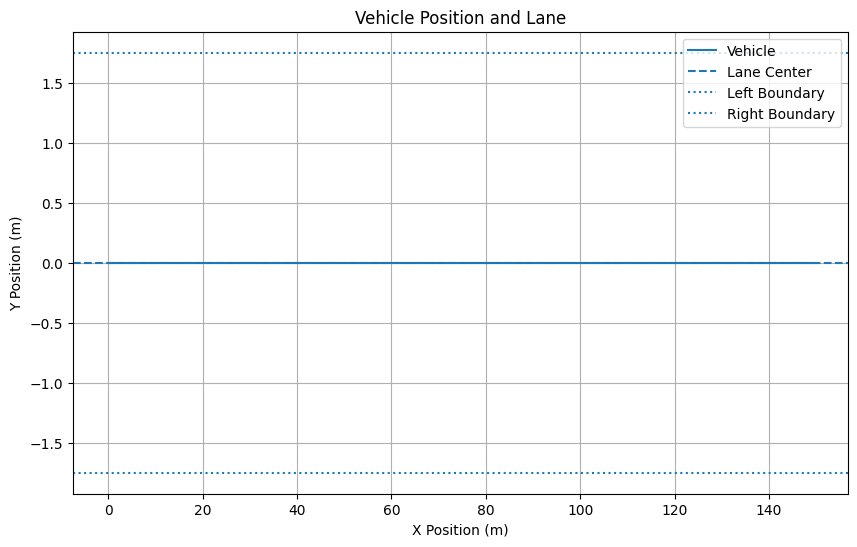

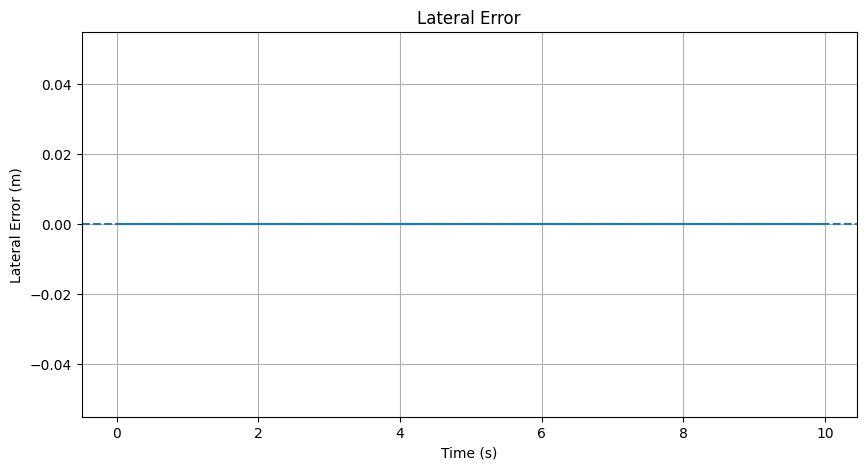

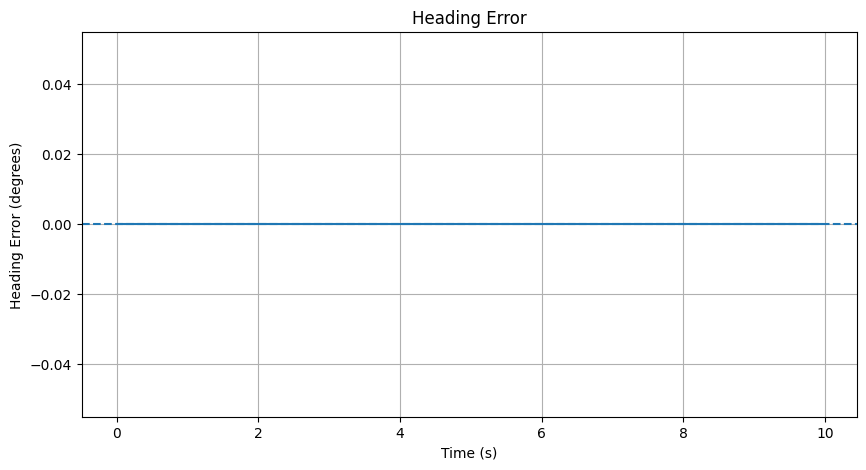

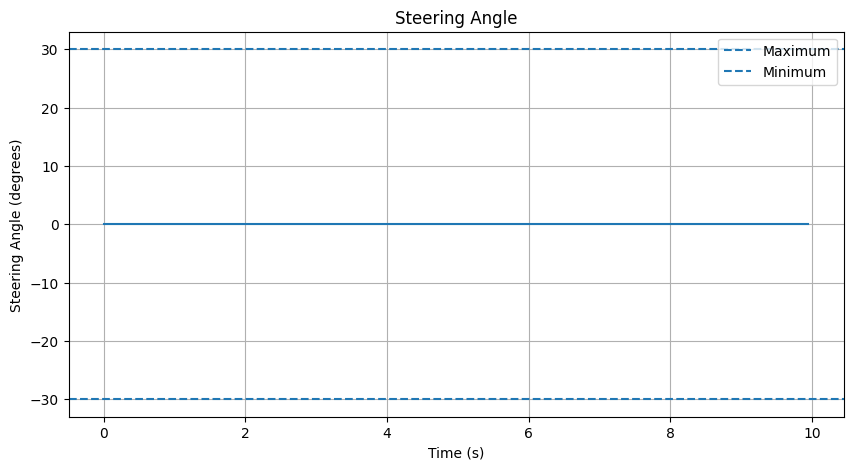


LANE DEPARTURE
Departure detected: False
Number of detected steps: 0


In [18]:
"""
Calcula los límites izquierdo y derecho del carril.
left_boundary  = center + width / 2
right_boundary = center - width / 2
"""
def calculate_lane_boundaries(lane_center, lane_width):
    left_boundary = lane_center + lane_width / 2
    right_boundary = lane_center - lane_width / 2

    return left_boundary, right_boundary

"""
Calcula el error lateral.
    e_y = y_vehicle - y_lane
"""
def calculate_lateral_error(vehicle_y, lane_center):
    lateral_error = vehicle_y - lane_center

    return lateral_error

"""
Calcula el error de orientación.
    e_psi = psi_vehicle - psi_lane
"""
def calculate_heading_error(vehicle_yaw, lane_heading):
    heading_error = vehicle_yaw - lane_heading

    return heading_error

"""
Calcula el ángulo de dirección deseado.
delta =
  -(K_lateral * lateral_error
  + K_heading * heading_error)
Posteriormente se limita el resultado.
"""
def calculate_steering_angle(lateral_error, heading_error):
    steering_angle = -(
        K_LATERAL * lateral_error +
        K_HEADING * heading_error
    )

    steering_angle = np.clip(
        steering_angle,
        -MAX_STEERING_ANGLE,
        MAX_STEERING_ANGLE
    )

    return steering_angle

"""
Modelo cinemático de bicicleta.
    x_dot   = v * cos(yaw)
    y_dot   = v * sin(yaw)
    yaw_dot = v/L * tan(delta)
"""
def bicycle_model(x, y, yaw, speed, steering_angle):
    x_dot = speed * np.cos(yaw)

    y_dot = speed * np.sin(yaw)

    yaw_dot = (
        speed / WHEELBASE
    ) * np.tan(steering_angle)

    return x_dot, y_dot, yaw_dot

"""
Actualiza la posición del vehículo
utilizando el modelo cinemático.
"""
def update_vehicle_state(x, y, yaw, speed, steering_angle, dt):
    x_dot, y_dot, yaw_dot = bicycle_model(
        x,
        y,
        yaw,
        speed,
        steering_angle
    )

    x_new = x + x_dot * dt

    y_new = y + y_dot * dt

    yaw_new = yaw + yaw_dot * dt

    return x_new, y_new, yaw_new

"""
    Determina si el vehículo está saliendo del carril.
    Se considera el ancho del vehículo y un margen
    de seguridad.
    TRUE  = existe riesgo de salida
    FALSE = permanece dentro del carril
"""
def detect_lane_departure(vehicle_y, lane_center, lane_width, vehicle_width):
    left_boundary = (lane_center + lane_width / 2)
    right_boundary = (lane_center - lane_width / 2)
    vehicle_left = (vehicle_y + vehicle_width / 2)
    vehicle_right = (vehicle_y - vehicle_width / 2)
    safe_left_boundary = (left_boundary - LANE_SAFETY_MARGIN)
    safe_right_boundary = (right_boundary + LANE_SAFETY_MARGIN)
    departure = (vehicle_left > safe_left_boundary or vehicle_right < safe_right_boundary)

    return departure

"""
Crea un objeto simulado.
Posteriormente estos datos pueden venir de:
    - Cámara
    - Radar
    - LiDAR
    - Sensor fusion
"""
def create_object(object_id, x, y, speed, lane):
    return {
        "id": object_id,
        "x": x,
        "y": y,
        "speed": speed,
        "lane": lane
    }

# ============================================================
# 13. DISTANCE BETWEEN VEHICLES
# ============================================================

def calculate_distance(
    vehicle_x,
    vehicle_y,
    object_x,
    object_y
):

    """
    Distancia euclidiana entre el vehículo
    y un objeto.
    """

    dx = object_x - vehicle_x

    dy = object_y - vehicle_y

    distance = np.sqrt(
        dx**2 + dy**2
    )

    return distance


# ============================================================
# 14. RELATIVE SPEED
# ============================================================

def calculate_relative_speed(
    vehicle_speed,
    object_speed
):

    """
    Velocidad relativa.

    Positiva:
        El vehículo se aproxima al objeto.

    Negativa:
        El objeto se aleja.
    """

    relative_speed = (
        vehicle_speed -
        object_speed
    )

    return relative_speed


# ============================================================
# 15. TTC
# ============================================================

def calculate_ttc(
    distance,
    relative_speed
):

    """
    Time To Collision.

    TTC = distance / relative_speed

    Si relative_speed <= 0:
        No existe aproximación.

    En ese caso se devuelve infinito.
    """

    if relative_speed <= 0:

        return np.inf

    ttc = (
        distance /
        relative_speed
    )

    return ttc


# ============================================================
# 16. TARGET LANE DETECTION
# ============================================================

def get_target_lane(
    current_lane,
    direction
):

    """
    Determina el carril objetivo.

    direction:
        "LEFT"
        "RIGHT"
    """

    if direction == "LEFT":

        return current_lane + 1

    elif direction == "RIGHT":

        return current_lane - 1

    else:

        return None


# ============================================================
# 17. CHECK TARGET LANE
# ============================================================

def check_target_lane(
    target_lane,
    objects
):

    """
    Revisa si existen vehículos en el carril objetivo.
    """

    target_objects = []

    for obj in objects:

        if obj["lane"] == target_lane:

            target_objects.append(obj)

    return target_objects


# ============================================================
# 18. CHECK SAFE DISTANCE
# ============================================================

def check_safe_distance(
    distance
):

    """
    Comprueba si la distancia es suficiente.
    """

    return (
        distance >=
        MIN_SAFE_DISTANCE
    )


# ============================================================
# 19. CHECK SAFE TTC
# ============================================================

def check_safe_ttc(
    ttc
):

    """
    Comprueba si el TTC es suficientemente alto.
    """

    if np.isinf(ttc):

        return True

    return (
        ttc >=
        MIN_SAFE_TTC
    )


# ============================================================
# 20. LANE CHANGE VALIDATION
# ============================================================

def can_change_lane(
    direction,
    vehicle_x,
    vehicle_y,
    vehicle_speed,
    current_lane,
    objects
):

    """
    Decide si el vehículo puede cambiar de carril.

    TRUE:
        El cambio cumple las condiciones.

    FALSE:
        No se puede demostrar que sea seguro.
    """

    # --------------------------------------------------------
    # TARGET LANE
    # --------------------------------------------------------

    target_lane = get_target_lane(
        current_lane,
        direction
    )

    if target_lane is None:

        return False


    # --------------------------------------------------------
    # OBJECTS IN TARGET LANE
    # --------------------------------------------------------

    target_objects = check_target_lane(
        target_lane,
        objects
    )


    # --------------------------------------------------------
    # NO OBJECTS
    # --------------------------------------------------------

    if len(target_objects) == 0:

        return True


    # --------------------------------------------------------
    # CHECK EACH OBJECT
    # --------------------------------------------------------

    for obj in target_objects:

        distance = calculate_distance(
            vehicle_x,
            vehicle_y,
            obj["x"],
            obj["y"]
        )

        relative_speed = calculate_relative_speed(
            vehicle_speed,
            obj["speed"]
        )

        ttc = calculate_ttc(
            distance,
            relative_speed
        )


        # --------------------------------------------
        # SAFE DISTANCE
        # --------------------------------------------

        distance_safe = check_safe_distance(
            distance
        )


        # --------------------------------------------
        # SAFE TTC
        # --------------------------------------------

        ttc_safe = check_safe_ttc(
            ttc
        )


        # --------------------------------------------
        # IF OBJECT IS NOT SAFE
        # --------------------------------------------

        if not distance_safe:

            return False

        if not ttc_safe:

            return False


    # --------------------------------------------------------
    # ALL CONDITIONS PASSED
    # --------------------------------------------------------

    return True


# ============================================================
# 21. SIMULATED OBJECTS
# ============================================================

objects = [

    create_object(
        object_id=1,
        x=40.0,
        y=3.5,
        speed=13.0,
        lane=1
    ),

    create_object(
        object_id=2,
        x=70.0,
        y=-3.5,
        speed=15.0,
        lane=-1
    )

]


# ============================================================
# 22. INITIAL VEHICLE STATE
# ============================================================

x = 0.0
y = 0.0
yaw = 0.0

speed = VEHICLE_SPEED


# ============================================================
# 23. SIMULATION ARRAYS
# ============================================================

time_history = []

x_history = []

y_history = []

yaw_history = []

lateral_error_history = []

heading_error_history = []

steering_history = []

lane_departure_history = []


# ============================================================
# 24. MAIN SIMULATION
# ============================================================

time = 0.0


while time <= SIMULATION_TIME:

    # --------------------------------------------------------
    # GET VEHICLE DATA
    # --------------------------------------------------------

    vehicle_data = get_vehicle_data()

    speed = vehicle_data["speed"]


    # --------------------------------------------------------
    # GET LANE DATA
    # --------------------------------------------------------

    lane_data = get_lane_data()

    lane_center = lane_data["center"]

    lane_heading = lane_data["heading"]

    lane_width = lane_data["width"]


    # --------------------------------------------------------
    # CALCULATE ERRORS
    # --------------------------------------------------------

    lateral_error = calculate_lateral_error(
        y,
        lane_center
    )

    heading_error = calculate_heading_error(
        yaw,
        lane_heading
    )


    # --------------------------------------------------------
    # CALCULATE STEERING
    # --------------------------------------------------------

    steering_angle = calculate_steering_angle(
        lateral_error,
        heading_error
    )


    # --------------------------------------------------------
    # LANE DEPARTURE
    # --------------------------------------------------------

    lane_departure = detect_lane_departure(
        y,
        lane_center,
        lane_width,
        VEHICLE_WIDTH
    )


    # --------------------------------------------------------
    # SAVE DATA
    # --------------------------------------------------------

    time_history.append(time)

    x_history.append(x)

    y_history.append(y)

    yaw_history.append(yaw)

    lateral_error_history.append(
        lateral_error
    )

    heading_error_history.append(
        heading_error
    )

    steering_history.append(
        steering_angle
    )

    lane_departure_history.append(
        lane_departure
    )


    # --------------------------------------------------------
    # UPDATE VEHICLE
    # --------------------------------------------------------

    x, y, yaw = update_vehicle_state(
        x,
        y,
        yaw,
        speed,
        steering_angle,
        DT
    )


    # --------------------------------------------------------
    # TIME
    # --------------------------------------------------------

    time += DT


# ============================================================
# 25. LANE CHANGE TEST
# ============================================================

current_lane = 0


can_left = can_change_lane(
    direction="LEFT",
    vehicle_x=x,
    vehicle_y=y,
    vehicle_speed=speed,
    current_lane=current_lane,
    objects=objects
)


can_right = can_change_lane(
    direction="RIGHT",
    vehicle_x=x,
    vehicle_y=y,
    vehicle_speed=speed,
    current_lane=current_lane,
    objects=objects
)


print("==========================================")
print("LANE CHANGE VALIDATION")
print("==========================================")

print(
    "Can change LEFT:",
    can_left
)

print(
    "Can change RIGHT:",
    can_right
)


# ============================================================
# 26. RESULTS
# ============================================================

print()
print("==========================================")
print("SIMULATION RESULTS")
print("==========================================")

print(
    "Final X:",
    round(x, 3),
    "m"
)

print(
    "Final Y:",
    round(y, 3),
    "m"
)

print(
    "Final Yaw:",
    round(
        np.rad2deg(yaw),
        3
    ),
    "degrees"
)

print(
    "Final lateral error:",
    round(
        lateral_error_history[-1],
        3
    ),
    "m"
)

print(
    "Final steering:",
    round(
        np.rad2deg(
            steering_history[-1]
        ),
        3
    ),
    "degrees"
)


# ============================================================
# 27. PLOT — VEHICLE POSITION
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    x_history,
    y_history,
    label="Vehicle"
)

plt.axhline(
    LANE_CENTER,
    linestyle="--",
    label="Lane Center"
)

plt.axhline(
    LANE_CENTER + LANE_WIDTH / 2,
    linestyle=":",
    label="Left Boundary"
)

plt.axhline(
    LANE_CENTER - LANE_WIDTH / 2,
    linestyle=":",
    label="Right Boundary"
)

plt.xlabel("X Position (m)")

plt.ylabel("Y Position (m)")

plt.title(
    "Vehicle Position and Lane"
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# 28. PLOT — LATERAL ERROR
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    time_history,
    lateral_error_history
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Time (s)"
)

plt.ylabel(
    "Lateral Error (m)"
)

plt.title(
    "Lateral Error"
)

plt.grid(True)

plt.show()


# ============================================================
# 29. PLOT — HEADING ERROR
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    time_history,
    np.rad2deg(
        heading_error_history
    )
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Time (s)"
)

plt.ylabel(
    "Heading Error (degrees)"
)

plt.title(
    "Heading Error"
)

plt.grid(True)

plt.show()


# ============================================================
# 30. PLOT — STEERING
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    time_history,
    np.rad2deg(
        steering_history
    )
)

plt.axhline(
    np.rad2deg(
        MAX_STEERING_ANGLE
    ),
    linestyle="--",
    label="Maximum"
)

plt.axhline(
    -np.rad2deg(
        MAX_STEERING_ANGLE
    ),
    linestyle="--",
    label="Minimum"
)

plt.xlabel(
    "Time (s)"
)

plt.ylabel(
    "Steering Angle (degrees)"
)

plt.title(
    "Steering Angle"
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# 31. LANE DEPARTURE RESULTS
# ============================================================

lane_departure_count = sum(
    lane_departure_history
)

print()
print("==========================================")
print("LANE DEPARTURE")
print("==========================================")

print(
    "Departure detected:",
    any(lane_departure_history)
)

print(
    "Number of detected steps:",
    lane_departure_count
)